In [8]:

import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv("movies.csv")
df




,Unnamed: 0,Title,Rating,Year,Month,Certificate,Runtime,Directors,Stars,Genre,Filming_location,Budget,Income,Country_of_origin
0,0,Avatar: The Way of Water,7.8,2022,December,PG-13,192,James Cameron,"Sam Worthington, Zoe Saldana, Sigourney Weaver...","Action, Adventure, Fantasy",New Zealand,"$350,000,000","$2,267,946,983",United States
1,1,Guillermo del Toro's Pinocchio,7.6,2022,December,PG,117,"Guillermo del Toro, Mark Gustafson","Ewan McGregor, David Bradley, Gregory Mann, Bu...","Animation, Drama, Family",USA,"$35,000,000","$108,967","United States, Mexico, France"
2,2,Bullet Train,7.3,2022,August,R,127,David Leitch,"Brad Pitt, Joey King, Aaron Taylor Johnson, Br...","Action, Comedy, Thriller",Japan,"$85,900,000","$239,268,602","Japan, United States"
3,3,The Banshees of Inisherin,7.8,2022,November,R,114,Martin McDonagh,"Colin Farrell, Brendan Gleeson, Kerry Condon, ...","Comedy, Drama",Ireland,Unknown,"$19,720,823","Ireland, United Kingdom, United States"
4,4,M3gan,6.4,2022,December,PG-13,102,Gerard Johnstone,"Jenna Davis, Amie Donald, Allison Williams, Vi...","Horror, Sci-Fi, Thriller",New Zealand,"$12,000,000","$171,253,910",United States
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,1995,A Tale of Two Sisters,7.1,2003,June,R,114,Jee woon Kim,"Lim Soo jung, Yum Jung ah, Kim Kap su, Moon Ge...","Drama, Horror, Mystery",South Korea,Unknown,"$1,062,878",South Korea
1996,1996,Lara Croft Tomb Raider: The Cradle of Life,5.5,2003,July,PG-13,117,Jan de Bont,"Angelina Jolie, Gerard Butler, Chris Barrie, C...","Action, Adventure, Fantasy",Greece,"$95,000,000","$160,099,222","United States, Germany, Japan, United Kingdom,..."
1997,1997,Gothika,5.8,2003,November,R,98,Mathieu Kassovitz,"Halle Berry, Pen lope Cruz, Robert Downey Jr ,...","Horror, Mystery, Thriller",Canada,"$40,000,000","$141,591,324","United States, France, Canada, Spain"
1998,1998,Ong-Bak: The Thai Warrior,7.1,2003,February,R,105,Prachya Pinkaew,"Tony Jaa, Phetthai Vongkumlao, Pumwaree Yodkam...","Action, Crime, Thriller",Thailand,Unknown,"$20,235,426","Thailand, France, Hong Kong"


#### Budget and Income contain dollar signs, commas, and some "Unknown" values.

In [14]:

# Create a copy so the original dataset remains unchanged
movies = df.copy()

# Convert Budget and Income into numeric values
movies["Budget"] = pd.to_numeric(
    movies["Budget"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .replace("Unknown", ""),
    errors="coerce"
)

movies["Income"] = pd.to_numeric(
    movies["Income"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .replace("Unknown", ""),
    errors="coerce"
)

# Convert Runtime to numeric
movies["Runtime"] = pd.to_numeric(
    movies["Runtime"], errors="coerce"
)

# Check the cleaned data
movies[["Title", "Budget", "Income", "Runtime"]].head()


,Title,Budget,Income,Runtime
0,Avatar: The Way of Water,350000000.0,2.267947e+09,192.0
1,Guillermo del Toro's Pinocchio,35000000.0,1.089670e+05,117.0
2,Bullet Train,85900000.0,2.392686e+08,127.0
3,The Banshees of Inisherin,NaN,1.972082e+07,114.0
4,M3gan,12000000.0,1.712539e+08,102.0


### 1. Average Revenue by Genre
- Which movie genres generate the highest average revenue?

#### The analysis shows that Animation generates the highest average revenue among all movie genres in the dataset.

Genre
Animation    4.222530e+08
Adventure    4.076870e+08
Sci-Fi       3.468177e+08
Action       3.054896e+08
Fantasy      2.962820e+08
Family       2.771165e+08
Musical      1.874793e+08
Comedy       1.681537e+08
Thriller     1.431331e+08
Music        1.156031e+08
Name: Income, dtype: float64


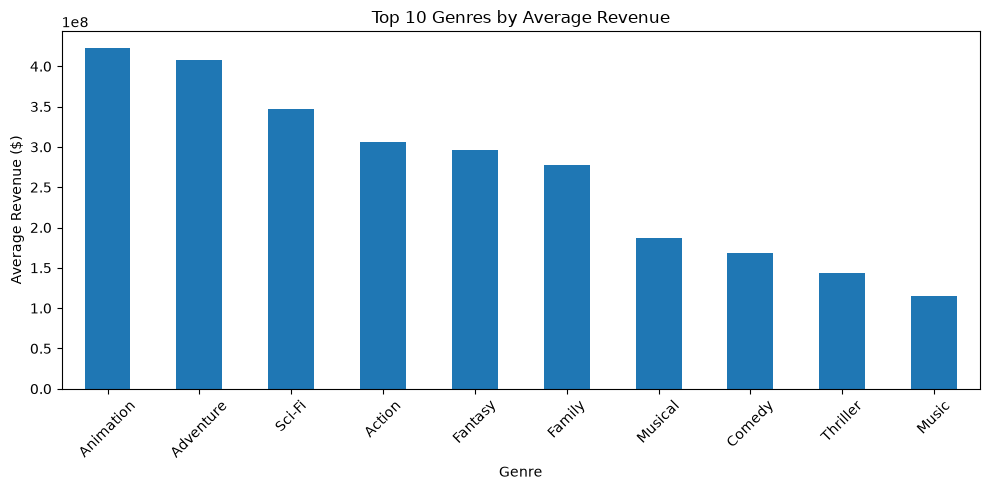

In [15]:

# Split movies with multiple genres into separate rows
genre_movies = movies.assign(
    Genre=movies["Genre"].str.split(", ")
).explode("Genre")

# Remove rows where Income is missing
genre_movies = genre_movies.dropna(subset=["Income"])

# Calculate average revenue for each genre
genre_revenue = genre_movies.groupby("Genre")["Income"].mean()

# Display the top 10 genres
top_genres = genre_revenue.sort_values(ascending=False).head(10)

print(top_genres)

# Draw a bar chart
top_genres.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Genres by Average Revenue")
plt.xlabel("Genre")
plt.ylabel("Average Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 2. Budget and Revenue Correlation
- Is there a correlation between a movie's budget and its revenue?

The analysis shows a positive correlation between movie budget and revenue, indicating that movies with higher budgets tend to generate higher revenues.

Budget-Revenue Correlation: 0.736744032981831


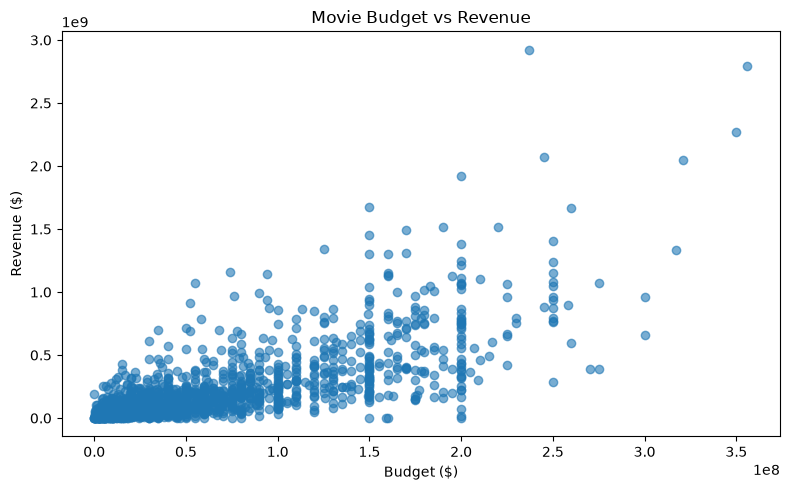

In [16]:

# Select movies that have both Budget and Income
budget_income = movies.dropna(
    subset=["Budget", "Income"]
)

# Calculate correlation
correlation = budget_income["Budget"].corr(
    budget_income["Income"]
)

print("Budget-Revenue Correlation:", correlation)

# Draw a scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    budget_income["Budget"],
    budget_income["Income"],
    alpha=0.6
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget ($)")
plt.ylabel("Revenue ($)")
plt.tight_layout()
plt.show()


### 3. Most Profitable Movies
- Which movies were the most profitable?
- Profit = Revenue - Budget

The analysis shows that Avatar is the most profitable movie in the dataset, with an estimated profit of approximately $2.69 billion, followed by Avengers: Endgame with approximately $2.44 billion.

                                           Title       Budget        Income  \
1300                                      Avatar  237000000.0  2.922918e+09   
305                            Avengers: Endgame  356000000.0  2.797501e+09   
0                       Avatar: The Way of Water  350000000.0  2.267947e+09   
714   Star Wars: Episode VII - The Force Awakens  245000000.0  2.069522e+09   
405                       Avengers: Infinity War  321000000.0  2.048360e+09   
103                      Spider-Man: No Way Home  200000000.0  1.917430e+09   
723                               Jurassic World  150000000.0  1.671537e+09   
344                                The Lion King  260000000.0  1.663250e+09   
753                                    Furious 7  190000000.0  1.515341e+09   
27                             Top Gun: Maverick  170000000.0  1.488733e+09   

            Profit  
1300  2.685918e+09  
305   2.441501e+09  
0     1.917947e+09  
714   1.824522e+09  
405   1.727360e+09  
103 

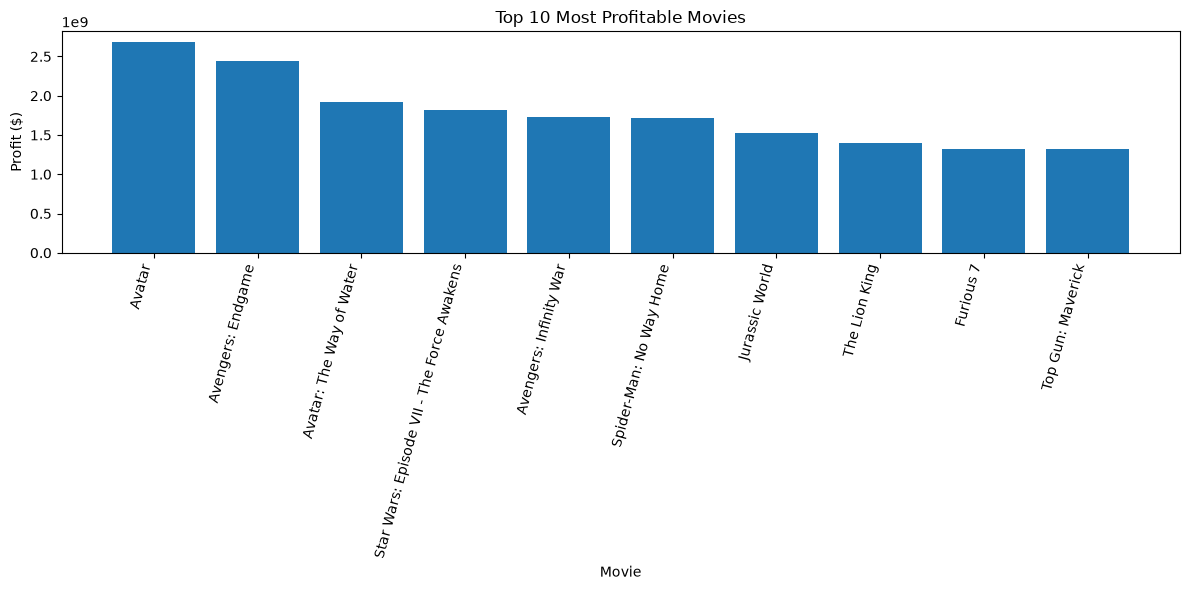

In [17]:

# Keep movies with known Budget and Income
profitable_movies = movies.dropna(
    subset=["Budget", "Income"]
).copy()

# Calculate profit
profitable_movies["Profit"] = (
    profitable_movies["Income"] -
    profitable_movies["Budget"]
)

# Display the 10 most profitable movies
top_profit = profitable_movies.sort_values(
    by="Profit", ascending=False
).head(10)

print(
    top_profit[["Title", "Budget", "Income", "Profit"]]
)

# Draw a bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    top_profit["Title"],
    top_profit["Profit"]
)

plt.title("Top 10 Most Profitable Movies")
plt.xlabel("Movie")
plt.ylabel("Profit ($)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


### 4. Ratings and Box Office Revenue
- Do movies with higher ratings earn more at the box office?

#### No, Movies with higher ratings tend to earn slightly more at the box office.

Rating-Revenue Correlation: 0.18296044502820408


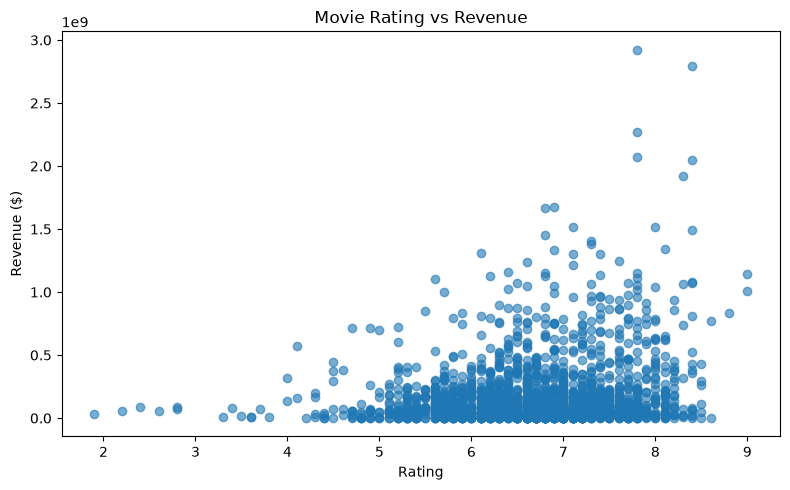

In [18]:

# Select rows with both Rating and Income
rating_income = movies.dropna(
    subset=["Rating", "Income"]
)

# Calculate correlation
rating_correlation = rating_income["Rating"].corr(
    rating_income["Income"]
)

print("Rating-Revenue Correlation:", rating_correlation)

# Draw a scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    rating_income["Rating"],
    rating_income["Income"],
    alpha=0.6
)

plt.title("Movie Rating vs Revenue")
plt.xlabel("Rating")
plt.ylabel("Revenue ($)")
plt.tight_layout()
plt.show()


### 5. Directors and Movie Ratings
- Which directors consistently produce high-rated movies?

#### Christopher Nolan consistently produces highly rated movies, with the highest average rating of 8.33 across 8 movies in the dataset.

                   Average_Rating  Movie_Count
Directors                                     
Christopher Nolan        8.325000            8
Quentin Tarantino        7.866667            9
Denis Villeneuve         7.828571            7
Martin Scorsese          7.828571            7
Park Chan wook           7.680000            5
David Fincher            7.666667            6
Bong Joon Ho             7.650000            6
Peter Jackson            7.633333            6
Clint Eastwood           7.630000           10
Wes Anderson             7.585714            7


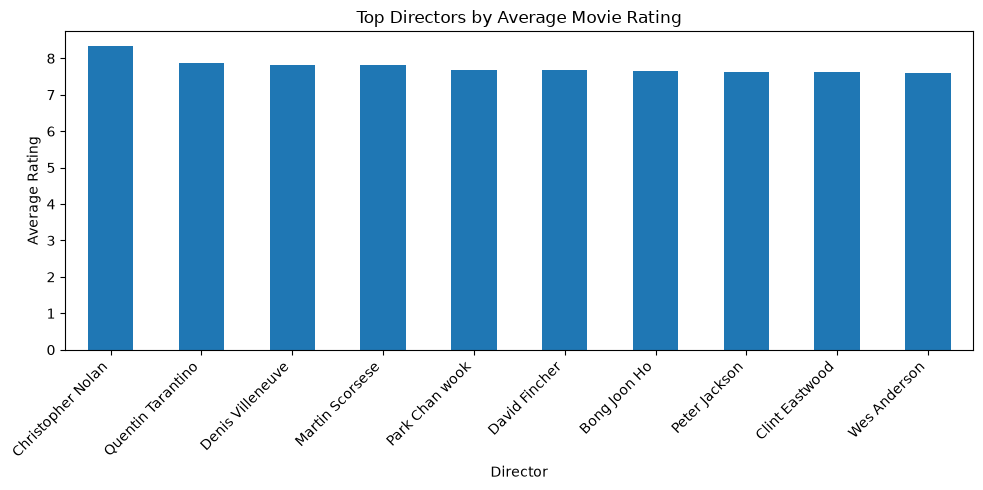

In [19]:

# Split rows containing multiple directors
director_movies = movies.assign(
    Directors=movies["Directors"].str.split(", ")
).explode("Directors")

# Remove missing ratings
director_movies = director_movies.dropna(
    subset=["Rating"]
)

# Calculate average rating and movie count
director_stats = director_movies.groupby(
    "Directors"
).agg(
    Average_Rating=("Rating", "mean"),
    Movie_Count=("Title", "count")
)

# Consider directors with at least 5 movies
consistent_directors = director_stats[
    director_stats["Movie_Count"] >= 5
]

# Sort by average rating
top_directors = consistent_directors.sort_values(
    by="Average_Rating", ascending=False
).head(10)

print(top_directors)

# Draw a bar chart
top_directors["Average_Rating"].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Top Directors by Average Movie Rating")
plt.xlabel("Director")
plt.ylabel("Average Rating")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### 6. Movies Released per Year
- How has the number of movies released per year changed over time?

#### The dataset shows a stable trend in movie releases, with exactly 100 movies recorded each year, indicating consistent yearly representation.

Year
2003    100
2004    100
2005    100
2006    100
2007    100
2008    100
2009    100
2010    100
2011    100
2012    100
2013    100
2014    100
2015    100
2016    100
2017    100
2018    100
2019    100
2020    100
2021    100
2022    100
Name: Title, dtype: int64


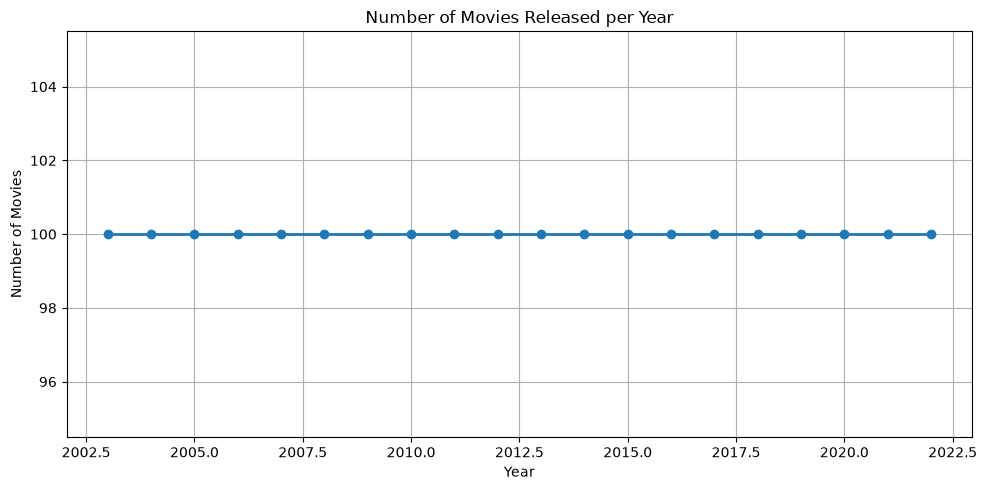

In [20]:

# Count movies released in each year
movies_per_year = movies.groupby("Year")["Title"].count()

print(movies_per_year)

# Draw a line chart
plt.figure(figsize=(10, 5))

plt.plot(
    movies_per_year.index,
    movies_per_year.values,
    marker="o",
    linewidth=2
)

plt.title("Number of Movies Released per Year")
plt.xlabel("Year")
plt.ylabel("Number of Movies")
plt.grid(True)
plt.tight_layout()
plt.show()


### 7. Trending Movie Genre
- Which genre is trending recently, based on the highest growth in the number of releases?

#### Horror is the fastest-growing genre by number of releases, increasing from 55 movies to 70 movies, a growth of 15 releases (27.27%) between the two periods.

In [21]:

# Use the genre_movies DataFrame created in Question 1

# Select movies from the two periods
earlier = genre_movies[
    (genre_movies["Year"] >= 2013) &
    (genre_movies["Year"] <= 2017)
]

recent = genre_movies[
    (genre_movies["Year"] >= 2018) &
    (genre_movies["Year"] <= 2022)
]

# Count releases by genre in each period
earlier_count = earlier.groupby("Genre")["Title"].count()
recent_count = recent.groupby("Genre")["Title"].count()

# Combine the counts into one DataFrame
genre_growth = pd.DataFrame({
    "Earlier_Releases": earlier_count,
    "Recent_Releases": recent_count
}).fillna(0)

# Calculate the change in number of releases
genre_growth["Growth"] = (
    genre_growth["Recent_Releases"] -
    genre_growth["Earlier_Releases"]
)

# Calculate percentage growth
genre_growth["Growth_Percentage"] = (
    genre_growth["Growth"] /
    genre_growth["Earlier_Releases"].replace(0, float("nan"))
) * 100

# Sort by the increase in release count
top_trending_genres = genre_growth.sort_values(
    by="Growth", ascending=False
).head(10)

print(top_trending_genres)


           Earlier_Releases  Recent_Releases  Growth  Growth_Percentage
Genre                                                                  
Horror                   55               70      15          27.272727
History                  12               17       5          41.666667
War                       4                9       5         125.000000
Musical                   2                4       2         100.000000
Mystery                  51               53       2           3.921569
Sport                     1                3       2         200.000000
Music                    10               10       0           0.000000
Animation                22               22       0           0.000000
Western                   4                2      -2         -50.000000
Thriller                 82               77      -5          -6.097561


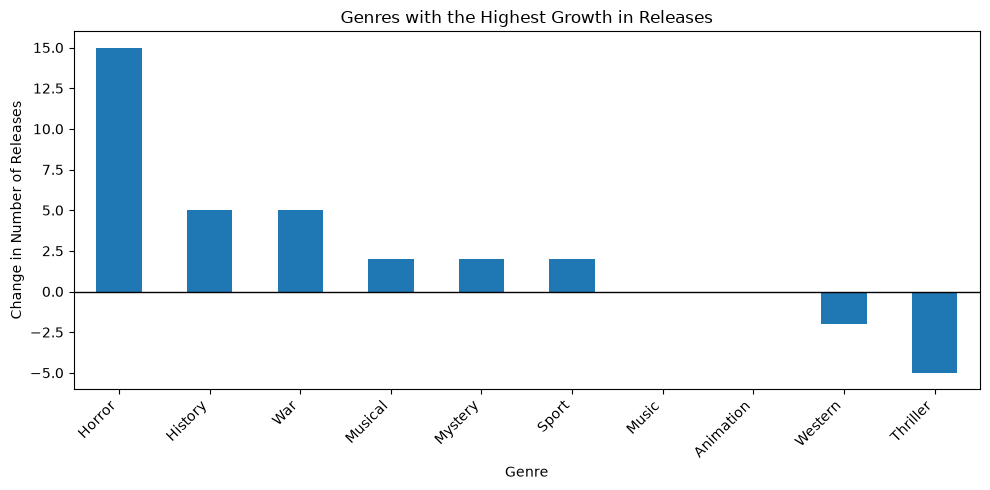

In [22]:

# Draw a bar chart of the top 10 genres by growth
top_trending_genres["Growth"].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Genres with the Highest Growth in Releases")
plt.xlabel("Genre")
plt.ylabel("Change in Number of Releases")
plt.xticks(rotation=45, ha="right")
plt.axhline(y=0, color="black", linewidth=1)
plt.tight_layout()
plt.show()


In [23]:
df.to_csv('Task2.csv', index=True)
# To save a new file